In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

class Source:
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def generate_directions(self, E: float) -> np.ndarray:
        N = np.random.poisson(lam=self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, size=N)
        cos_theta = np.random.uniform(-1.0, 1.0, size=N)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        return np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))


class Detector:
    def __init__(self, R: float = 2.0, N: int = 40, r: float = 0.1, a: float = 0.5,
                 attenuation_length: float | None = 8.0):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)
        self.attenuation_length = attenuation_length
        self.pmt_coords = self._generate_pmt_positions()

    def _generate_pmt_positions(self) -> np.ndarray:
        indices = np.arange(0, self.N, dtype=float) + 0.5
        z = self.R * (1 - 2 * indices / self.N)
        rho = np.sqrt(self.R**2 - z**2)
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        theta = golden_angle * indices
        x = rho * np.cos(theta)
        y = rho * np.sin(theta)
        return np.column_stack((x, y, z))

    def detect_photons(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        origin = np.asarray(origin, dtype=float)
        b = np.sum(directions * origin, axis=1)
        c = np.sum(origin**2) - self.R**2
        t = -b + np.sqrt(b**2 - c)
        hit_points = origin + t[:, None] * directions

        if self.attenuation_length is not None:
            survived = np.random.uniform(0.0, 1.0, size=len(t)) < np.exp(-t / self.attenuation_length)
            hit_points = hit_points[survived]

        hits_per_pmt = np.zeros(self.N, dtype=int)
        for i, pmt_center in enumerate(self.pmt_coords):
            distances = np.linalg.norm(hit_points - pmt_center, axis=1)
            hits_per_pmt[i] = np.sum(distances <= self.r)
        return np.random.poisson(lam=self.a * hits_per_pmt)


# Фиксируем seed для воспроизводимости сгенерированного события
np.random.seed(42)

detector = Detector(R=2.0, N=40, r=0.1, a=0.5, attenuation_length=8.0)
source = Source(Y=10000)

# Задаем ИСТИННЫЕ параметры события (которые мы потом будем восстанавливать)
E_true = 2.0
origin_true = np.array([0.5, -0.6, 0.8])

# Генерируем отклик детектора (число ф.э. на каждом из 40 ФЭУ)
directions_sim = source.generate_directions(E=E_true)
pe_observed = detector.detect_photons(origin=origin_true, directions=directions_sim)

print(f"Истинные параметры: E = {E_true} МэВ, (x, y, z) = {origin_true} м")
print(f"Суммарное число фотоэлектронов: {np.sum(pe_observed)} ф.э.")
print(f"Отклик по 40 каналам ФЭУ:\n{pe_observed}")

Истинные параметры: E = 2.0 МэВ, (x, y, z) = [ 0.5 -0.6  0.8] м
Суммарное число фотоэлектронов: 203 ф.э.
Отклик по 40 каналам ФЭУ:
[10  3 16  3 15  6  2 33  5 10  4  1 16  1  2  8  3  7  5  2  8  3  4  3
  1  1  1  1  6  1  3  0  0  5  4  1  3  3  3  0]


In [2]:
pmt_coords_pt = pt.constant(detector.pmt_coords)

with pm.Model() as recon_model:
    # Априорные распределения
    E = pm.Uniform('E', lower=0.1, upper=5.0)
    x = pm.Uniform('x', lower=-1.1, upper=1.1)
    y = pm.Uniform('y', lower=-1.1, upper=1.1)
    z = pm.Uniform('z', lower=-1.1, upper=1.1)

    origin_pt = pt.stack([x, y, z])

    # Вычисляем расстояние d_i от точки (x, y, z) до каждого из N=40 ФЭУ
    diff = pmt_coords_pt - origin_pt[None, :]
    d = pt.sqrt(pt.sum(diff**2, axis=1))

    # Косинус угла падения фотонов на поверхность сферы в точке каждого ФЭУ
    cos_alpha = pt.sum(diff * pmt_coords_pt, axis=1) / (d * detector.R)

    # Геометрическая вероятность попадания в каждый ФЭУ
    geom_prob = (detector.r**2 * cos_alpha) / (4.0 * d**2)

    # Учет затухания света в сцинтилляторе (L = 8 м)
    att_factor = pt.exp(-d / detector.attenuation_length)

    # Ожидаемое среднее число фотоэлектронов mu_i в каждом из 40 ФЭУ
    mu_pmt = detector.a * source.Y * E * geom_prob * att_factor

    # Правдоподобие (Likelihood): связываем модель с наблюдаемыми данными pe_observed
    y_obs = pm.Poisson('y_obs', mu=mu_pmt, observed=pe_observed)

    # Запуск MCMC сэмплирования для получения апостериорного распределения
    posterior = pm.sample(draws=2000, tune=1000, chains=4)

Output()

=== РЕЗУЛЬТАТЫ РЕКОНСТРУКЦИИ ===
E: Истинное =  2.00 МэВ | Восстановленное =  2.04 ± 0.14 МэВ | 95% интервал: [ 1.77,  2.33]
x: Истинное =  0.50 м | Восстановленное =  0.43 ± 0.06 м | 95% интервал: [ 0.31,  0.56]
y: Истинное = -0.60 м | Восстановленное = -0.76 ± 0.07 м | 95% интервал: [-0.90, -0.61]
z: Истинное =  0.80 м | Восстановленное =  0.88 ± 0.09 м | 95% интервал: [ 0.72,  1.06]


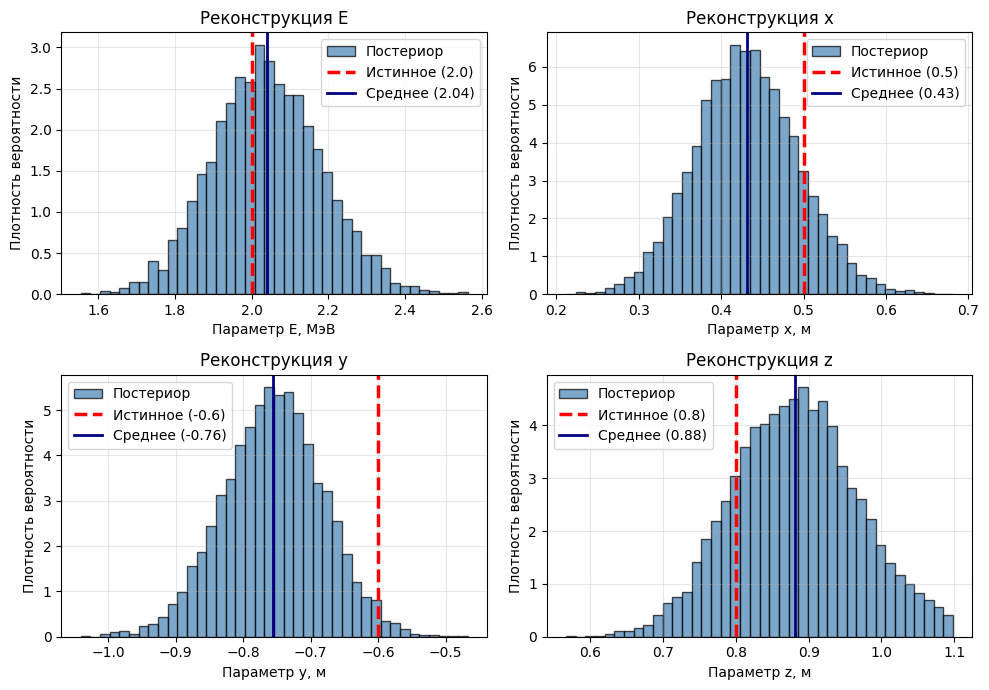

In [3]:
# Достаем сэмплы из постериора
post = posterior.posterior
params = ['E', 'x', 'y', 'z']
true_values = {'E': E_true, 'x': origin_true[0], 'y': origin_true[1], 'z': origin_true[2]}
units = {'E': 'МэВ', 'x': 'м', 'y': 'м', 'z': 'м'}

print("=== РЕЗУЛЬТАТЫ РЕКОНСТРУКЦИИ ===")
for name in params:
    samples = post[name].values.flatten()
    mean_val = np.mean(samples)
    std_val = np.std(samples)
    ci_low, ci_high = np.percentile(samples, [2.5, 97.5]) # 95% доверительный интервал

    print(f"{name}: Истинное = {true_values[name]:5.2f} {units[name]} | "
          f"Восстановленное = {mean_val:5.2f} ± {std_val:4.2f} {units[name]} | "
          f"95% интервал: [{ci_low:5.2f}, {ci_high:5.2f}]")

# Строим графики апостериорных распределений и истинных значений
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()

for i, name in enumerate(params):
    samples = post[name].values.flatten()
    axes[i].hist(samples, bins=40, density=True, alpha=0.7, color='steelblue', edgecolor='black', label='Постериор')
    axes[i].axvline(true_values[name], color='red', lw=2.5, linestyle='--', label=f'Истинное ({true_values[name]})')
    axes[i].axvline(np.mean(samples), color='navy', lw=2, label=f'Среднее ({np.mean(samples):.2f})')
    axes[i].set_xlabel(f'Параметр {name}, {units[name]}')
    axes[i].set_ylabel('Плотность вероятности')
    axes[i].set_title(f'Реконструкция {name}')
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()